In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
# -----------------------
# Parameters
# -----------------------
TICKER = "SPY"
START = "2000-01-01"
END = "2020-01-01"

FRED_SERIES = "USEPUINDXD"  # Economic Policy Uncertainty index
SIGNAL_MA = 5
LOOKBACK = 756
QUANTILE = 0.90

In [ ]:
# -----------------------
# Load price data
# -----------------------
df = yf.download(TICKER, start=START, end=END, auto_adjust=True)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[['Close']].copy()

[*********************100%***********************]  1 of 1 completed


In [ ]:
# -----------------------
# Load news / sentiment data (FRED)
# -----------------------
url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={FRED_SERIES}"
epu = pd.read_csv(url, parse_dates=["observation_date"])
epu = epu.rename(columns={"observation_date": "Date", FRED_SERIES: "EPU"})
epu = epu.set_index("Date")[["EPU"]]
epu["EPU"] = pd.to_numeric(epu["EPU"], errors="coerce")

In [ ]:
# -----------------------
# Merge datasets
# -----------------------
df = df.join(epu, how="left")
df["EPU"] = df["EPU"].ffill()

df["Returns"] = df["Close"].pct_change()

In [ ]:
# -----------------------
# Build sentiment signal
# -----------------------
epu_ma = df["EPU"].rolling(SIGNAL_MA).mean()

threshold = (
    epu_ma.shift(1)
    .rolling(LOOKBACK)
    .quantile(QUANTILE)
)

In [ ]:
# -----------------------
# Trading rule
# -----------------------
# Invest when uncertainty is NOT extreme
position = (epu_ma < threshold).astype(int)

# shift to avoid lookahead bias
strategy_returns = position.shift(1) * df["Returns"]

In [ ]:
# -----------------------
# Compute performance
# -----------------------
cumulative_strategy = (1 + strategy_returns).cumprod()
cumulative_benchmark = (1 + df["Returns"]).cumprod()

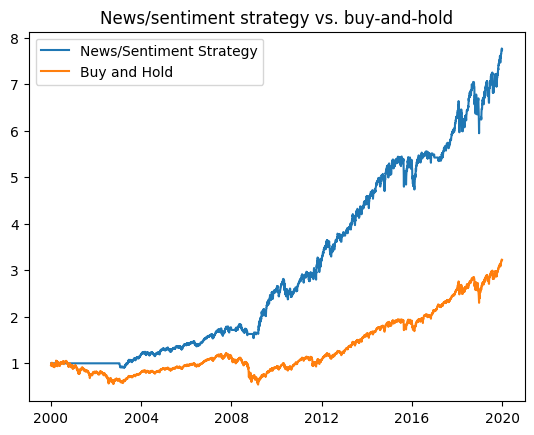

In [ ]:
# -----------------------
# Plot results
# -----------------------
plt.title("News/sentiment strategy vs. buy-and-hold")
plt.plot(cumulative_strategy, label="News/Sentiment Strategy")
plt.plot(cumulative_benchmark, label="Buy and Hold")
plt.legend(loc="upper left")
plt.show()